# 04 - Perbandingan Tiga Model

Tiga model dibandingkan pada **split dan fitur yang sama**:
1. Logistic Regression baseline dengan fitur asli,
2. Random Forest,
3. LightGBM dengan early stopping.

Data test April-Juni 2026 **tidak disentuh**. Semua pemilihan model dan
threshold hanya memakai validation Januari-Maret 2026.

In [1]:
from pathlib import Path
import sys
import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.features import build_features, make_logistic_preprocessor

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.alpha": 0.25,
})

# Baca lalu langsung potong ke train/validation. Test tidak dibuat atau dipakai.
semua = pd.read_csv(ROOT / "data" / "clean.csv", parse_dates=["tanggal_pickup"])
train = semua.loc[semua["tanggal_pickup"] <= "2025-12-31"].copy()
valid = semua.loc[semua["tanggal_pickup"].between("2026-01-01", "2026-03-31")].copy()
del semua

assert train["tanggal_pickup"].max() <= pd.Timestamp("2025-12-31")
assert valid["tanggal_pickup"].min() >= pd.Timestamp("2026-01-01")
assert valid["tanggal_pickup"].max() <= pd.Timestamp("2026-03-31")

print("Train     :", len(train), "| rasio terlambat:", round(train["terlambat"].mean(), 4))
print("Validation:", len(valid), "| rasio terlambat:", round(valid["terlambat"].mean(), 4))

Train     : 26633 | rasio terlambat: 0.1778
Validation: 6623 | rasio terlambat: 0.2188


## Fitur dan preprocessing yang sama

Ketiga model memakai 10 fitur asli dan preprocessing yang identik. Imputer,
scaler, dan one-hot encoder di-fit hanya pada train.

In [2]:
ORIG_NUM = [
    "jam_pickup",
    "jarak_km",
    "jumlah_transit",
    "janji_hari",
    "berat_kg",
    "volume_hub_hari",
]
ORIG_CAT = ["kota_tujuan", "layanan", "metode_bayar", "cuaca_saat_pickup"]
ORIG_FEATURES = ORIG_NUM + ORIG_CAT

X_train = train[ORIG_FEATURES]
X_valid = valid[ORIG_FEATURES]
y_train = train["terlambat"]
y_valid = valid["terlambat"]

preprocessor = ColumnTransformer(
    [
        (
            "numerik",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            ORIG_NUM,
        ),
        (
            "kategorikal",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            ORIG_CAT,
        ),
    ],
    remainder="drop",
)

X_train_t = preprocessor.fit_transform(X_train)
X_valid_t = preprocessor.transform(X_valid)
print("Bentuk fitur setelah preprocessing:", X_train_t.shape)

Bentuk fitur setelah preprocessing: (26633, 30)


## Tuning ringan pada validation

Grid kecil dicoba satu per satu. Skor yang dipakai adalah PR-AUC validation.
LightGBM memakai early stopping pada validation dengan metrik `average_precision`.

In [3]:
RANDOM_STATE = 42
rasio_kelas = float((y_train == 0).sum() / (y_train == 1).sum())


def coba_model(nama, estimator, parameter, pakai_early_stopping=False):
    model = clone(estimator).set_params(**parameter)
    mulai = time.perf_counter()

    if pakai_early_stopping:
        model.fit(
            X_train_t,
            y_train,
            eval_X=X_valid_t,
            eval_y=y_valid,
            eval_metric="average_precision",
            callbacks=[lgb.early_stopping(30, verbose=False)],
        )
    else:
        model.fit(X_train_t, y_train)

    durasi = time.perf_counter() - mulai
    probabilitas = model.predict_proba(X_valid_t)[:, 1]
    return {
        "nama": nama,
        "param": parameter,
        "pr_auc": average_precision_score(y_valid, probabilitas),
        "roc_auc": roc_auc_score(y_valid, probabilitas),
        "detik": durasi,
        "model": model,
        "proba": probabilitas,
    }


grid_logistik = {
    "C": [0.1, 1.0, 10.0],
    "class_weight": [None, "balanced"],
}
grid_rf = {
    "n_estimators": [200],
    "min_samples_leaf": [1, 5],
    "class_weight": [None, "balanced_subsample"],
}
grid_lgb = {
    "n_estimators": [500],
    "learning_rate": [0.03, 0.1],
    "num_leaves": [15, 31],
    "scale_pos_weight": [1, round(rasio_kelas, 2)],
}

hasil_grid = []

for param in ParameterGrid(grid_logistik):
    hasil_grid.append(coba_model(
        "Logistic Regression",
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        param,
    ))

for param in ParameterGrid(grid_rf):
    hasil_grid.append(coba_model(
        "Random Forest",
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        param,
    ))

for param in ParameterGrid(grid_lgb):
    hasil_grid.append(coba_model(
        "LightGBM",
        lgb.LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1, force_col_wise=True),
        param,
        pakai_early_stopping=True,
    ))

terbaik = {}
for nama in ["Logistic Regression", "Random Forest", "LightGBM"]:
    kandidat = [h for h in hasil_grid if h["nama"] == nama]
    terbaik[nama] = max(kandidat, key=lambda h: h["pr_auc"])
    print(f"{nama}: {terbaik[nama]['param']} | PR-AUC={terbaik[nama]['pr_auc']:.4f}")

print("Rasio negatif/positif pada train:", round(rasio_kelas, 3))

Logistic Regression: {'C': 10.0, 'class_weight': None} | PR-AUC=0.6458
Random Forest: {'class_weight': None, 'min_samples_leaf': 5, 'n_estimators': 200} | PR-AUC=0.6382
LightGBM: {'learning_rate': 0.03, 'n_estimators': 500, 'num_leaves': 15, 'scale_pos_weight': 1} | PR-AUC=0.6553
Rasio negatif/positif pada train: 4.625


## Hasil utama

Tabel berikut membandingkan tiga model pada fitur dan split yang sama.
Waktu latih diukur dari pemanggilan `fit` saja (detik).

In [4]:
urutan = ["Logistic Regression", "Random Forest", "LightGBM"]
tabel_hasil = pd.DataFrame(
    [
        {
            "model": nama,
            "PR-AUC val": terbaik[nama]["pr_auc"],
            "ROC-AUC val": terbaik[nama]["roc_auc"],
            "train time": terbaik[nama]["detik"],
        }
        for nama in urutan
    ]
)
tabel_hasil["PR-AUC val"] = tabel_hasil["PR-AUC val"].round(4)
tabel_hasil["ROC-AUC val"] = tabel_hasil["ROC-AUC val"].round(4)
tabel_hasil["train time"] = tabel_hasil["train time"].round(2)
tabel_hasil

,model,PR-AUC val,ROC-AUC val,train time
0,Logistic Regression,0.6458,0.8311,0.06
1,Random Forest,0.6382,0.8322,0.70
2,LightGBM,0.6553,0.8396,0.89


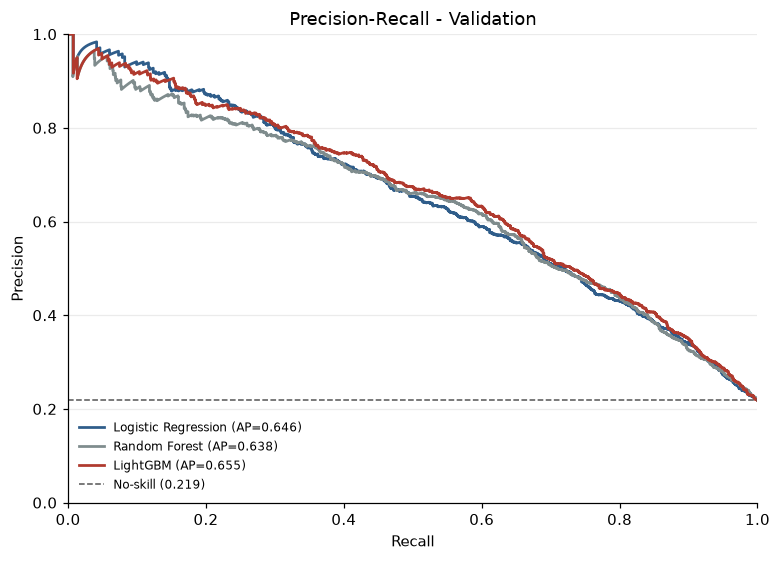

In [5]:
warna = {"Logistic Regression": "#2f5d8a", "Random Forest": "#7f8c8d", "LightGBM": "#b03a2e"}

fig, ax = plt.subplots(figsize=(7.2, 5.2))
for nama in urutan:
    presisi, recall, _ = precision_recall_curve(y_valid, terbaik[nama]["proba"])
    ax.plot(
        recall,
        presisi,
        color=warna[nama],
        linewidth=1.8,
        label=f"{nama} (AP={terbaik[nama]['pr_auc']:.3f})",
    )

ax.axhline(y_valid.mean(), color="#555555", linestyle="--", linewidth=1,
           label=f"No-skill ({y_valid.mean():.3f})")
ax.set_title("Precision-Recall - Validation")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_pr_curves_models.png", dpi=160, bbox_inches="tight")
plt.show()

## Fitur rekayasa versus fitur asli

Logistik dengan fitur rekayasa memakai `build_features` dari `src/features.py`.
Fitur ini **tidak memakai** `volume_hub_hari` karena risiko kebocoran informasi.
Perbandingan ini memakai konfigurasi logistik terbaik dari grid di atas.

In [6]:
X_train_e = build_features(train)
X_valid_e = build_features(valid)

prep_e = make_logistic_preprocessor()
X_train_e_t = prep_e.fit_transform(X_train_e)
X_valid_e_t = prep_e.transform(X_valid_e)

logistik_e = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, **terbaik["Logistic Regression"]["param"])
logistik_e.fit(X_train_e_t, y_train)
proba_e = logistik_e.predict_proba(X_valid_e_t)[:, 1]

print(f"Logistik fitur asli     : PR-AUC={terbaik['Logistic Regression']['pr_auc']:.4f}, ROC-AUC={terbaik['Logistic Regression']['roc_auc']:.4f}")
print(f"Logistik fitur rekayasa : PR-AUC={average_precision_score(y_valid, proba_e):.4f}, ROC-AUC={roc_auc_score(y_valid, proba_e):.4f}")
print(f"Fitur rekayasa dipakai  : {X_train_e.shape[1]} kolom, tanpa volume_hub_hari")

Logistik fitur asli     : PR-AUC=0.6458, ROC-AUC=0.8311
Logistik fitur rekayasa : PR-AUC=0.4093, ROC-AUC=0.6874
Fitur rekayasa dipakai  : 18 kolom, tanpa volume_hub_hari


Fitur rekayasa menurun tajam dibanding fitur asli. Penyebab paling mungkin:
`volume_hub_hari` sengaja dihapus karena risiko kebocoran, padahal EDA menunjukkan
fitur itu sangat kuat. Ini trade-off antara performa dan keabsahan prediksi saat
pickup. Sampai tersedia volume berjalan yang benar-benar diketahui saat pickup,
builder ini belum dipakai untuk model final.

## Efek penanganan imbalance terhadap kalibrasi

Bobot kelas (`class_weight` dan `scale_pos_weight`) bisa menaikkan recall, tetapi
probabilitas yang dihasilkan tidak lagi merepresentasikan peluang asli. Ini bisa
merusak kalibrasi dan membuat threshold biaya Rp50.000/Rp5.000 tidak akurat.
Cek kalibrasi dan Brier score dilakukan pada tahap berikutnya.

In [7]:
def berbobot(param):
    return param.get("class_weight") is not None or float(param.get("scale_pos_weight", 1)) != 1.0


for nama in urutan:
    kandidat = [h for h in hasil_grid if h["nama"] == nama]
    tanpa = max((h for h in kandidat if not berbobot(h["param"])), key=lambda h: h["pr_auc"])
    dengan = max((h for h in kandidat if berbobot(h["param"])), key=lambda h: h["pr_auc"])
    selisih = dengan["pr_auc"] - tanpa["pr_auc"]
    arah = "menaikkan" if selisih > 0 else "menurunkan"
    print(
        f"{nama}: tanpa bobot {tanpa['pr_auc']:.4f}; dengan bobot {dengan['pr_auc']:.4f}; "
        f"bobot {arah} PR-AUC {abs(selisih):.4f}"
    )

Logistic Regression: tanpa bobot 0.6458; dengan bobot 0.6449; bobot menurunkan PR-AUC 0.0009
Random Forest: tanpa bobot 0.6382; dengan bobot 0.6353; bobot menurunkan PR-AUC 0.0029
LightGBM: tanpa bobot 0.6553; dengan bobot 0.6042; bobot menurunkan PR-AUC 0.0511


## Pemilihan model final

Pilihan memakai PR-AUC validation. Jika selisihnya kecil, model lebih sederhana
dan lebih mudah dijelaskan yang dipilih.

In [8]:
baseline = terbaik["Logistic Regression"]
paling_tinggi = max([terbaik[nama] for nama in urutan], key=lambda h: h["pr_auc"])
selisih = paling_tinggi["pr_auc"] - baseline["pr_auc"]

if paling_tinggi["nama"] == "Logistic Regression" or selisih < 0.01:
    pilihan = baseline
    alasan = (
        "Kenaikan model kompleks kecil atau tidak ada, jadi regresi logistik dipilih "
        "karena lebih mudah dijelaskan kepada staf dan lebih stabil untuk threshold biaya."
    )
else:
    pilihan = paling_tinggi
    alasan = (
        f"Kenaikan PR-AUC {selisih:.4f} dianggap cukup bermakna dibanding baseline, "
        "jadi model dengan skor validation tertinggi dipilih."
    )

print("Model final:", pilihan["nama"])
print("Alasan:", alasan)
print(f"PR-AUC validation: {pilihan['pr_auc']:.4f}")
print(f"ROC-AUC validation: {pilihan['roc_auc']:.4f}")

if paling_tinggi["nama"] != "Logistic Regression" and paling_tinggi["pr_auc"] <= baseline["pr_auc"]:
    print(
        "Catatan jujur: model kompleks tidak mengalahkan baseline. Data sintetik ini "
        "memiliki pola yang relatif sederhana; sinyal utama sudah tertangkap fitur asli, "
        "dan tuning sengaja dibatasi agar tidak menyesuaikan validation berlebih."
    )

if paling_tinggi["nama"] != "Logistic Regression" and 0 < selisih < 0.01:
    print(
        f"Catatan jujur: {paling_tinggi['nama']} unggul {selisih:.4f} PR-AUC, "
        "tetapi selisihnya berada di bawah batas 0,01. Kenaikan kecil ini belum cukup "
        "untuk mengorbankan kemudahan penjelasan regresi logistik."
    )

Model final: Logistic Regression
Alasan: Kenaikan model kompleks kecil atau tidak ada, jadi regresi logistik dipilih karena lebih mudah dijelaskan kepada staf dan lebih stabil untuk threshold biaya.
PR-AUC validation: 0.6458
ROC-AUC validation: 0.8311
Catatan jujur: LightGBM unggul 0.0095 PR-AUC, tetapi selisihnya berada di bawah batas 0,01. Kenaikan kecil ini belum cukup untuk mengorbankan kemudahan penjelasan regresi logistik.


Data test April-Juni 2026 belum dibuka, tidak diprediksi, dan tidak dipakai untuk
memilih model ataupun parameter.